In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)


In [2]:
df = pd.read_csv("Iris - Iris.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print("Shape of dataset:", df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())
print("\nTarget Classes:")
print(df['Species'].value_counts())

Shape of dataset: (150, 6)

Column Names:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical Summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000



Target Classes:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [4]:
X = df.drop(columns=['Species', 'Id'])

# Target variable
y = df['Species']

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:
Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'], dtype='object')

Target:
Species

Feature shape: (150, 4)
Target shape: (150,)


In [5]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_encoded = le.fit_transform(y)

print("Class names:")
print(le.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Class names:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']

Encoded classes:
[0 1 2]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 105
Testing samples: 45


In [7]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)

In [8]:
accuracy = accuracy_score(y_test, y_pred)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

roc_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class='ovr',
    average='weighted'
)

print("Accuracy :", round(accuracy, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Accuracy : 0.8889
F1 Score : 0.8878
ROC-AUC  : 0.9889


In [9]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_
    )
)

Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.78      0.93      0.85        15
 Iris-virginica       0.92      0.73      0.81        15

       accuracy                           0.89        45
      macro avg       0.90      0.89      0.89        45
   weighted avg       0.90      0.89      0.89        45



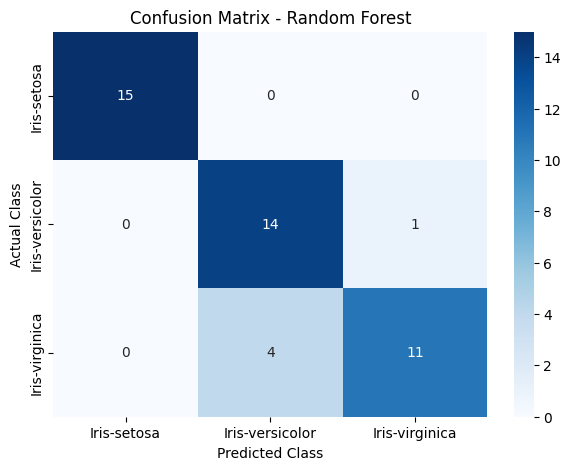

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Random Forest")

plt.show()

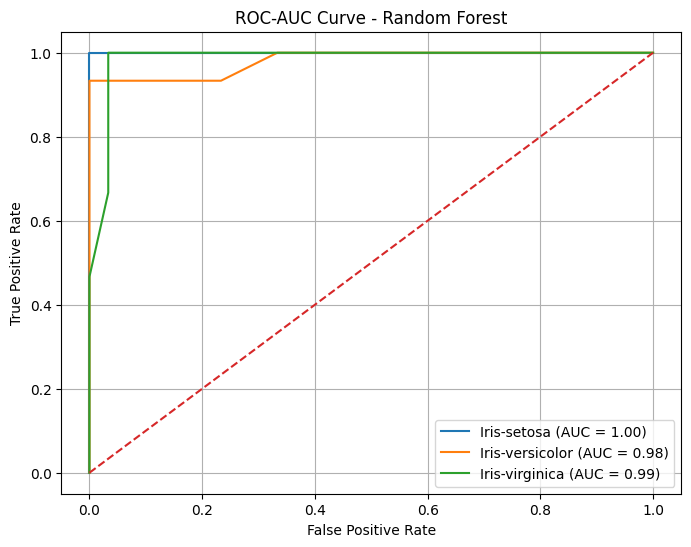

In [11]:
# Binarize target
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(le.classes_))
)

n_classes = len(le.classes_)

plt.figure(figsize=(8, 6))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    roc_auc_class = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{le.classes_[i]} (AUC = {roc_auc_class:.2f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Curve - Random Forest")

plt.legend()
plt.grid()

plt.show()

In [12]:
results = []

for i in range(5):

    seed = i + 1

    # Random 70:30 split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y_encoded,
        test_size=0.30,
        random_state=seed,
        stratify=y_encoded
    )

    # Random Forest
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=seed
    )

    rf.fit(X_train, y_train)

    # Predictions
    y_pred = rf.predict(X_test)
    y_prob = rf.predict_proba(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class='ovr',
        average='weighted'
    )

    results.append({
        'Run': seed,
        'Accuracy': accuracy,
        'F1 Score': f1,
        'ROC-AUC': roc_auc
    })


results_df = pd.DataFrame(results)

display(results_df)

,Run,Accuracy,F1 Score,ROC-AUC
0,1,0.977778,0.977753,1.000000
1,2,1.000000,1.000000,1.000000
2,3,0.911111,0.911111,0.992222
3,4,0.955556,0.955556,0.997037
4,5,0.933333,0.933259,0.985185


In [13]:
print("Average Performance Across 5 Runs:\n")
print("Mean Accuracy:",round(results_df['Accuracy'].mean(), 4))
print("Std Accuracy:",round(results_df['Accuracy'].std(), 4))
print("\nMean F1 Score:", round(results_df['F1 Score'].mean(), 4))
print("Std F1 Score:",round(results_df['F1 Score'].std(), 4))
print("\nMean ROC-AUC:",round(results_df['ROC-AUC'].mean(), 4))
print("Std ROC-AUC:",round(results_df['ROC-AUC'].std(), 4))

Average Performance Across 5 Runs:

Mean Accuracy: 0.9556
Std Accuracy: 0.0351

Mean F1 Score: 0.9555
Std F1 Score: 0.0351

Mean ROC-AUC: 0.9949
Std ROC-AUC: 0.0063


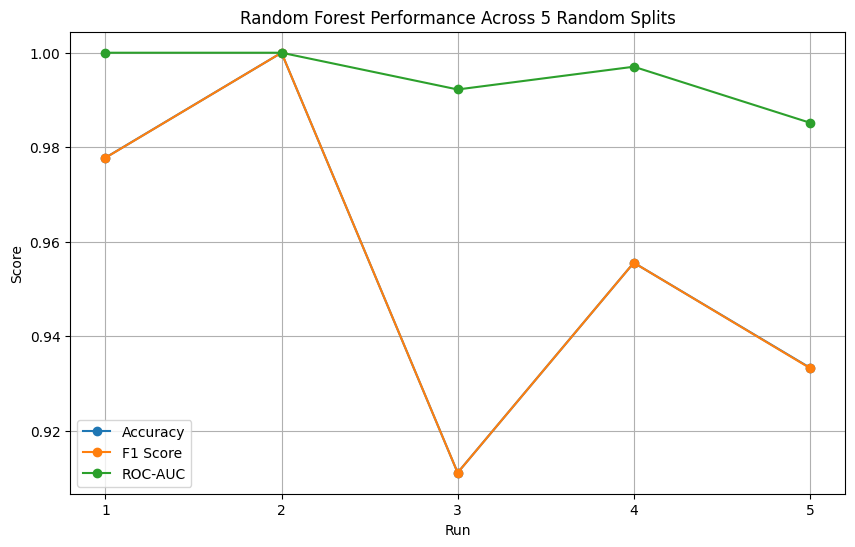

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df['Run'],
    results_df['Accuracy'],
    marker='o',
    label='Accuracy'
)

plt.plot(
    results_df['Run'],
    results_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.plot(
    results_df['Run'],
    results_df['ROC-AUC'],
    marker='o',
    label='ROC-AUC'
)

plt.xlabel("Run")
plt.ylabel("Score")
plt.title("Random Forest Performance Across 5 Random Splits")

plt.xticks(results_df['Run'])

plt.legend()
plt.grid()

plt.show()

In [15]:
# cross-validation
# K-Fold Cross Validation

from sklearn.model_selection import KFold, cross_validate

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'f1': 'f1_weighted',
    'roc_auc': 'roc_auc_ovr_weighted'
}

kfold_results = cross_validate(
    rf,
    X,
    y_encoded,
    cv=kfold,
    scoring=scoring
)

print("K-FOLD CROSS VALIDATION")

print("\nAccuracy for each fold:")
print(kfold_results['test_accuracy'])

print("\nF1 Score for each fold:")
print(kfold_results['test_f1'])

print("\nROC-AUC for each fold:")
print(kfold_results['test_roc_auc'])

print("\nMean Accuracy:",
      round(kfold_results['test_accuracy'].mean(), 4))

print("Mean F1 Score:",
      round(kfold_results['test_f1'].mean(), 4))

print("Mean ROC-AUC:",
      round(kfold_results['test_roc_auc'].mean(), 4))

K-FOLD CROSS VALIDATION

Accuracy for each fold:
[1.         0.96666667 0.93333333 0.93333333 0.96666667]

F1 Score for each fold:
[1.         0.96617827 0.93333333 0.93333333 0.96666667]

ROC-AUC for each fold:
[1.         1.         0.98727273 0.9912037  0.99639376]

Mean Accuracy: 0.96
Mean F1 Score: 0.9599
Mean ROC-AUC: 0.995


In [16]:
# Stratified K-Fold Cross Validation
from sklearn.model_selection import StratifiedKFold

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

stratified_results = cross_validate(
    rf,
    X,
    y_encoded,
    cv=stratified_kfold,
    scoring=scoring
)

print("STRATIFIED K-FOLD CROSS VALIDATION")

print("\nAccuracy for each fold:")
print(stratified_results['test_accuracy'])

print("\nF1 Score for each fold:")
print(stratified_results['test_f1'])

print("\nROC-AUC for each fold:")
print(stratified_results['test_roc_auc'])

print("\nMean Accuracy:",
      round(stratified_results['test_accuracy'].mean(), 4))

print("Mean F1 Score:",
      round(stratified_results['test_f1'].mean(), 4))

print("Mean ROC-AUC:",
      round(stratified_results['test_roc_auc'].mean(), 4))

STRATIFIED K-FOLD CROSS VALIDATION

Accuracy for each fold:
[0.96666667 0.96666667 0.93333333 0.96666667 0.9       ]

F1 Score for each fold:
[0.96658312 0.96658312 0.93265993 0.96658312 0.89974937]

ROC-AUC for each fold:
[1.         1.         0.99       1.         0.98166667]

Mean Accuracy: 0.9467
Mean F1 Score: 0.9464
Mean ROC-AUC: 0.9943


In [17]:
# Repeated K-Fold Cross Validation
from sklearn.model_selection import RepeatedKFold

repeated_kfold = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

repeated_results = cross_validate(
    rf,
    X,
    y_encoded,
    cv=repeated_kfold,
    scoring=scoring
)

print("REPEATED K-FOLD CROSS VALIDATION")

print("\nNumber of evaluations:",
      len(repeated_results['test_accuracy']))

print("\nAccuracy:")
print(repeated_results['test_accuracy'])

print("\nF1 Score:")
print(repeated_results['test_f1'])

print("\nROC-AUC:")
print(repeated_results['test_roc_auc'])

print("\nMean Accuracy:",
      round(repeated_results['test_accuracy'].mean(), 4))

print("Mean F1 Score:",
      round(repeated_results['test_f1'].mean(), 4))

print("Mean ROC-AUC:",
      round(repeated_results['test_roc_auc'].mean(), 4))

REPEATED K-FOLD CROSS VALIDATION

Number of evaluations: 15

Accuracy:
[1.         0.96666667 0.93333333 0.93333333 0.96666667 0.96666667
 1.         0.9        1.         0.93333333 0.96666667 0.86666667
 1.         1.         0.9       ]

F1 Score:
[1.         0.96617827 0.93333333 0.93333333 0.96666667 0.96594517
 1.         0.89810526 1.         0.93095238 0.96700623 0.86438746
 1.         1.         0.90598291]

ROC-AUC:
[1.         1.         0.98727273 0.9912037  0.99639376 0.99083333
 1.         0.98596491 1.         0.98783422 0.99603175 0.97453704
 1.         1.         0.99644444]

Mean Accuracy: 0.9556
Mean F1 Score: 0.9555
Mean ROC-AUC: 0.9938


In [18]:
cv_comparison = pd.DataFrame({
    'Method': [
        'K-Fold',
        'Stratified K-Fold',
        'Repeated K-Fold'
    ],

    'Mean Accuracy': [
        kfold_results['test_accuracy'].mean(),
        stratified_results['test_accuracy'].mean(),
        repeated_results['test_accuracy'].mean()
    ],

    'Mean F1 Score': [
        kfold_results['test_f1'].mean(),
        stratified_results['test_f1'].mean(),
        repeated_results['test_f1'].mean()
    ],

    'Mean ROC-AUC': [
        kfold_results['test_roc_auc'].mean(),
        stratified_results['test_roc_auc'].mean(),
        repeated_results['test_roc_auc'].mean()
    ]
})

display(
    cv_comparison.round(4)
)

,Method,Mean Accuracy,Mean F1 Score,Mean ROC-AUC
0,K-Fold,0.9600,0.9599,0.9950
1,Stratified K-Fold,0.9467,0.9464,0.9943
2,Repeated K-Fold,0.9556,0.9555,0.9938


In [19]:
cv_std = pd.DataFrame({
    'Method': [
        'K-Fold',
        'Stratified K-Fold',
        'Repeated K-Fold'
    ],

    'Accuracy Std': [
        kfold_results['test_accuracy'].std(),
        stratified_results['test_accuracy'].std(),
        repeated_results['test_accuracy'].std()
    ],

    'F1 Std': [
        kfold_results['test_f1'].std(),
        stratified_results['test_f1'].std(),
        repeated_results['test_f1'].std()
    ],

    'ROC-AUC Std': [
        kfold_results['test_roc_auc'].std(),
        stratified_results['test_roc_auc'].std(),
        repeated_results['test_roc_auc'].std()
    ]
})

display(
    cv_std.round(4)
)

,Method,Accuracy Std,F1 Std,ROC-AUC Std
0,K-Fold,0.0249,0.0249,0.0050
1,Stratified K-Fold,0.0267,0.0268,0.0074
2,Repeated K-Fold,0.0416,0.0416,0.0072


In [20]:
final_comparison = pd.DataFrame({
    'Technique': [
        'Random 70:30 Split (5 Runs)',
        'K-Fold CV',
        'Stratified K-Fold CV',
        'Repeated K-Fold CV'
    ],

    'Accuracy': [
        results_df['Accuracy'].mean(),
        kfold_results['test_accuracy'].mean(),
        stratified_results['test_accuracy'].mean(),
        repeated_results['test_accuracy'].mean()
    ],

    'F1 Score': [
        results_df['F1 Score'].mean(),
        kfold_results['test_f1'].mean(),
        stratified_results['test_f1'].mean(),
        repeated_results['test_f1'].mean()
    ],

    'ROC-AUC': [
        results_df['ROC-AUC'].mean(),
        kfold_results['test_roc_auc'].mean(),
        stratified_results['test_roc_auc'].mean(),
        repeated_results['test_roc_auc'].mean()
    ]
})

display(
    final_comparison.round(4)
)

,Technique,Accuracy,F1 Score,ROC-AUC
0,Random 70:30 Split (5 Runs),0.9556,0.9555,0.9949
1,K-Fold CV,0.9600,0.9599,0.9950
2,Stratified K-Fold CV,0.9467,0.9464,0.9943
3,Repeated K-Fold CV,0.9556,0.9555,0.9938


In [21]:
# The Random Forest classifier demonstrated good and consistent classification
# performance on the Iris dataset. Across five random 70:30 train-test splits,
# the model achieved an average accuracy of 95.56%, weighted F1-score of 95.55%,
# and ROC-AUC of 99.49%. The variation across the five runs indicates that model
# performance can depend on the random train-test partition.

# Among the cross-validation techniques, K-Fold Cross Validation achieved the
# highest average accuracy of 96.00%, F1-score of 95.99%, and ROC-AUC of 99.50%.
# Stratified K-Fold achieved 94.67% accuracy, while Repeated K-Fold achieved
# 95.56% accuracy. Overall, the Random Forest classifier showed strong and
# reliable performance across all evaluation techniques.